# **Datos Santiago**
---

Notebook de trabajo de la **Fase 2 · Entendimiento de los datos**. Corresponde a la actividad 10 del plan (*Diccionario de datos*): documentar cada variable, su tipo, su dominio y su papel en el proyecto.

Cubre el **componente de preconteo** (`PRE1v_MMV_9999_PRECONTEO.txt`), el MMV (*Mesa a Mesa con Votos*) del conteo rápido de la noche electoral de la primera vuelta presidencial del 31 de mayo de 2026.

Es un complemento del notebook principal `Copy_of_M2U3_fase_2_Entendimiento_de_los_datos`. La inspección física del archivo, la validación de tipos, la cardinalidad, la granularidad y las distribuciones de votos ya están allí y no se repiten aquí. Este notebook agrega el significado de cada variable, los códigos especiales y las gráficas descriptivas de la sección 3, incluido el cruce con el escrutinio.

## **1. Carga de los datos**
---



In [1]:
import hashlib
import zipfile
from pathlib import Path
import pandas as pd

DATA_DIR = Path(
    "../../data/raw/elecciones_2026/extracted/"
    "MMV_Presidente1V_2026/MMV_Presidente1V_2026"
)
EXTRACTED_DIR = DATA_DIR.parents[1]
DIR_BASICOS = EXTRACTED_DIR / "ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3"

assert DATA_DIR.is_dir(), f"No se encontró el directorio de datos: {DATA_DIR.resolve()}"

# Los catálogos vienen comprimidos; se extraen una sola vez en extracted/
if not (DIR_BASICOS / "HASH.txt").is_file():
    with zipfile.ZipFile(DATA_DIR / "ARCHIVOSBASICOS_AUDITORES_PRESIDENTE_2026_V3.zip") as z:
        z.extractall(EXTRACTED_DIR)

ARCH_PRECONTEO = DATA_DIR / "PRE1v_MMV_9999_PRECONTEO.txt"
assert ARCH_PRECONTEO.is_file(), "No se encontró el archivo de preconteo."
assert (DIR_BASICOS / "HASH.txt").is_file(), "No se encontraron los catálogos básicos."

In [2]:
def calcular_hash(ruta: Path, algoritmo: str = "md5") -> str:
    h = hashlib.new(algoritmo)
    with open(ruta, "rb") as f:
        for bloque in iter(lambda: f.read(1 << 20), b""):
            h.update(bloque)
    return h.hexdigest()

# MD5 del preconteo tomado del archivo HASH_*.txt de la RNEC
assert calcular_hash(ARCH_PRECONTEO) == "f957d26d6c9ab7eba8e25d14b48047ea", \
    "El preconteo no coincide con la huella publicada"

COLS_PRE   = ["dep", "mun", "zona", "puesto", "mesa", "jal", "comunicado",
              "circ", "partido", "candidato", "votos"]
ANCHOS_PRE = [2, 3, 2, 2, 6, 2, 4, 1, 5, 3, 8]
precon = pd.read_fwf(ARCH_PRECONTEO, widths=ANCHOS_PRE, names=COLS_PRE,
                     dtype=str, encoding="latin-1")
precon["votos"] = precon["votos"].astype("int64")

def leer_catalogo(prefijo: str, anchos, nombres) -> pd.DataFrame:
    ruta = next(DIR_BASICOS.glob(f"{prefijo}_*.TXT"))
    df = pd.read_fwf(ruta, widths=anchos, names=nombres, dtype=str, encoding="latin-1")
    return df.apply(lambda s: s.str.strip())

partidos = leer_catalogo("PARTIDOS", [5, 200], ["partido", "partido_nombre"])
candidatos = leer_catalogo(
    "CANDIDATOS", [3, 1, 2, 3, 2, 5, 3, 1, 50, 50, 15, 1, 2],
    ["corporacion", "circ", "dep", "mun", "comuna", "partido", "candidato",
     "preferente", "nombre", "apellido", "cedula", "genero", "sorteo"])
ESPECIALES = {"996": "VOTO EN BLANCO", "997": "VOTOS NULOS", "998": "VOTOS NO MARCADOS"}

# Normalización de llaves (igual que en la Fase 1)
LLAVE_MESA = ["dep", "mun", "zona", "puesto", "mesa"]
precon["zona"] = precon["zona"].str.zfill(3)
precon["partido"] = precon["partido"].str.zfill(5)

print(f"Preconteo: {len(precon):,} filas x {precon.shape[1]} columnas")
print(f"Mesas: {precon[LLAVE_MESA].drop_duplicates().shape[0]:,}")
precon.head()

Preconteo: 1,479,506 filas x 11 columnas


Mesas: 122,020


,dep,mun,zona,puesto,mesa,jal,comunicado,circ,partido,candidato,votos
0,01,001,001,01,000001,00,9999,0,00009,011,27
1,01,001,001,01,000001,00,9999,0,00015,012,5
2,01,001,001,01,000001,00,9999,0,00020,006,1
3,01,001,001,01,000001,00,9999,0,00021,010,0
4,01,001,001,01,000001,00,9999,0,00022,008,0


## **2. Diccionario de variables del preconteo**
---

El archivo es de **ancho fijo** y está en **formato largo**: cada fila es una combinación *mesa × candidatura* con votos. Las posiciones, longitudes y tipos oficiales de cada campo, así como la validación de que todos los registros los cumplen, están en el notebook principal (`Copy_of_M2U3_fase_2_Entendimiento_de_los_datos`, secciones *Documentación oficial y formato de almacenamiento* y *Validación de los campos según la documentación oficial*). Aquí se documenta el significado de cada variable y su papel en el proyecto.

| # | Variable | Descripción | Tipo estadístico | Dominio observado | Papel en el proyecto |
|---|---|---|---|---|---|
| 1 | `dep` | Código del departamento según la DIVIPOL de la RNEC (no coincide con el código DANE). El código `88` agrupa las mesas del exterior. | Categórica nominal | 34 códigos (`01`–`72` y `88`) | Llave de mesa; agrupación territorial y partición agrupada por departamento. |
| 2 | `mun` | Código del municipio dentro del departamento. Solo es único en combinación con `dep`; en el exterior (`dep = 88`) hay 67 códigos. | Categórica nominal | 309 códigos (`001`–`900`) | Llave de mesa; agrupación territorial. |
| 3 | `zona` | Código de la zona electoral dentro del municipio. Se normaliza a 3 dígitos (`zfill(3)`) para cruzar con escrutinio, novedades y DIVIPOL. | Categórica nominal | 52 códigos (`000`–`099`) | Llave de mesa. |
| 4 | `puesto` | Código del puesto de votación dentro de la zona. Es **alfanumérico**: además de `00`–`99` hay códigos como `A1` o `Z5`. | Categórica nominal | 208 códigos | Llave de mesa; unidad de comparación entre mesas del mismo puesto. |
| 5 | `mesa` | Número de la mesa dentro del puesto, con ceros a la izquierda. | Categórica nominal (identificador) | 228 códigos (`000001`–`000228`) | Llave de mesa; **unidad de análisis**. |
| 6 | `jal` | Código de comuna/JAL (Junta Administradora Local). No aplica a la elección presidencial. | Categórica (constante) | Un único valor (`00`) | Sin variabilidad: se descarta como predictor. |
| 7 | `comunicado` | Número del boletín del preconteo. `9999` identifica el consolidado final. | Categórica (constante) | Un único valor (`9999`) | Metadato de versión; se descarta como predictor. |
| 8 | `circ` | Código de circunscripción. La elección presidencial tiene circunscripción nacional única. | Categórica (constante) | Un único valor (`0`) | Sin variabilidad: se descarta como predictor. |
| 9 | `partido` | Código del partido o agrupación que inscribe la candidatura. Se normaliza a 5 dígitos (`zfill(5)`); se traduce con el catálogo `PARTIDOS`. Los códigos especiales 996, 997 y 998 llevan partido `00000`, que no está en el catálogo. | Categórica nominal | 14 códigos (13 partidos y `00000`) | Identifica la candidatura junto con `candidato`. |
| 10 | `candidato` | Código de la candidatura: `001`–`013` son los candidatos (catálogo `CANDIDATOS`); `996` voto en blanco, `997` votos nulos y `998` votos no marcados. | Categórica nominal | 16 códigos | Pivote para pasar a una fila por mesa; base de los indicadores de distribución y concentración del voto. |
| 11 | `votos` | Número de votos de la candidatura en la mesa según el preconteo. | Numérica discreta (conteo ≥ 0) | 0 – 694 (398 valores distintos) | Base de la variable de discrepancia preconteo–escrutinio (regresión) y de los indicadores para la detección de anomalías. |

**Llave de mesa.** Ninguna variable identifica la mesa por sí sola: la llave es la combinación `dep + mun + zona + puesto + mesa`, compartida con el escrutinio y las novedades tras la normalización. La llave de cada fila del preconteo es `llave de mesa + candidato`.

Los dominios observados se obtuvieron sobre el archivo completo. La celda siguiente los recalcula directamente sobre los datos.

In [3]:
DESCRIPCIONES = {
    "dep":        "Código del departamento (DIVIPOL RNEC)",
    "mun":        "Código del municipio dentro del departamento",
    "zona":       "Código de la zona electoral (normalizado a 3 dígitos)",
    "puesto":     "Código del puesto de votación dentro de la zona",
    "mesa":       "Número de la mesa dentro del puesto",
    "jal":        "Código de comuna/JAL (no aplica a presidencial)",
    "comunicado": "Número de boletín (9999 = consolidado final)",
    "circ":       "Código de circunscripción",
    "partido":    "Código del partido (normalizado a 5 dígitos)",
    "candidato":  "Código de candidatura (001-013, 996, 997, 998)",
    "votos":      "Votos de la candidatura en la mesa",
}
TIPO_ESTADISTICO = {c: "Categórica nominal" for c in COLS_PRE}
TIPO_ESTADISTICO["votos"] = "Numérica discreta"

def resumir_dominio(s: pd.Series) -> str:
    if pd.api.types.is_numeric_dtype(s):
        return f"[{s.min():,} – {s.max():,}]"
    valores = sorted(s.unique())
    if len(valores) <= 16:
        return ", ".join(valores)
    return f"{valores[0]} … {valores[-1]}"

diccionario_pre = pd.DataFrame({
    "variable": COLS_PRE,
    "descripcion": [DESCRIPCIONES[c] for c in COLS_PRE],
    "tipo_estadistico": [TIPO_ESTADISTICO[c] for c in COLS_PRE],
    "valores_unicos": precon[COLS_PRE].nunique().values,
    "dominio": [resumir_dominio(precon[c]) for c in COLS_PRE],
})
pd.set_option("display.max_colwidth", 120)
display(diccionario_pre)

,variable,descripcion,tipo_estadistico,valores_unicos,dominio
0,dep,Código del departamento (DIVIPOL RNEC),Categórica nominal,34,01 … 88
1,mun,Código del municipio dentro del departamento,Categórica nominal,309,001 … 900
2,zona,Código de la zona electoral (normalizado a 3 dígitos),Categórica nominal,52,000 … 099
3,puesto,Código del puesto de votación dentro de la zona,Categórica nominal,208,00 … Z5
4,mesa,Número de la mesa dentro del puesto,Categórica nominal,228,000001 … 000228
5,jal,Código de comuna/JAL (no aplica a presidencial),Categórica nominal,1,00
6,comunicado,Número de boletín (9999 = consolidado final),Categórica nominal,1,9999
7,circ,Código de circunscripción,Categórica nominal,1,0
8,partido,Código del partido (normalizado a 5 dígitos),Categórica nominal,14,"00000, 00009, 00015, 00020, 00021, 00022, 00026, 01001, 01002, 01003, 01004, 01005, 01006, 03001"
9,candidato,"Código de candidatura (001-013, 996, 997, 998)",Categórica nominal,16,"001, 002, 003, 004, 005, 006, 007, 008, 009, 010, 011, 012, 013, 996, 997, 998"


### **2.1. Códigos de candidatura y partido**
---

La variable `candidato` es la que da sentido a `votos`. El notebook principal traduce las 13 candidaturas ordinarias con los catálogos y describe sus votos (`Copy_of_M2U3_fase_2_Entendimiento_de_los_datos`, secciones *Interpretación de los códigos de candidatos* y *Distribución de votos por candidatura*). La tabla siguiente completa esa traducción con los tres códigos especiales (996, 997 y 998), que no están en los catálogos, para tener las 16 candidaturas del archivo en un solo lugar.

In [4]:
nombres_cand = (candidatos.assign(nombre_candidatura=candidatos["nombre"] + " " + candidatos["apellido"])
                [["candidato", "nombre_candidatura"]])
nombres_cand = pd.concat([nombres_cand,
                          pd.DataFrame(ESPECIALES.items(), columns=["candidato", "nombre_candidatura"])],
                         ignore_index=True)

codigos_cand = (precon[["candidato", "partido"]].drop_duplicates()
                .merge(nombres_cand, on="candidato", how="left")
                .merge(partidos.assign(partido=partidos["partido"].str.zfill(5)),
                       on="partido", how="left")
                .sort_values("candidato", ignore_index=True))
codigos_cand["partido_nombre"] = codigos_cand["partido_nombre"].fillna("(código especial, sin partido)")
display(codigos_cand[["candidato", "nombre_candidatura", "partido", "partido_nombre"]])

,candidato,nombre_candidatura,partido,partido_nombre
0,001,IVÁN CEPEDA CASTRO,00026,MOVIMIENTO POLÍTICO PACTO HISTÓRICO
1,002,CLAUDIA LÓPEZ,01004,CON CLAUDIA IMPARABLES
2,003,RAÚL SANTIAGO BOTERO JARAMILLO,01001,ROMPER EL SISTEMA
3,004,ABELARDO DE LA ESPRIELLA,01003,DEFENSORES DE LA PATRIA
4,005,ÓSCAR MAURICIO LIZCANO ARANGO,03001,COALICIÓN F.A.M.I.L.I.A
5,006,MIGUEL URIBE LONDOÑO,00020,PARTIDO DEMÓCRATA COLOMBIANO
6,007,SONDRA MACOLLINS GARVIN PINTO,01002,"SONDRA MACOLLINS, LA ABOGADA DE HIERRO"
7,008,ROY LEONARDO BARRERAS MONTEALEGRE,00022,PARTIDO POLÍTICO LA FUERZA
8,009,CARLOS EDUARDO CAICEDO OMAR,01006,CAICEDO
9,010,GUSTAVO MATAMOROS CAMACHO,00021,PARTIDO ECOLOGISTA COLOMBIANO


### **2.2. Observaciones sobre el preconteo**
---

Las observaciones sobre la estructura del archivo ya están documentadas en el notebook principal (`Copy_of_M2U3_fase_2_Entendimiento_de_los_datos`): `puesto` es alfanumérico, `jal`, `comunicado` y `circ` son constantes, las llaves deben conservarse como texto y cada mesa trae entre 1 y 16 filas. Aquí se agregan las que no están allí:

- **Las filas ausentes equivalen a cero votos.** Al pasar a una fila por mesa, las combinaciones *mesa × candidatura* que no vienen en el archivo deben rellenarse con 0, no tratarse como datos perdidos. La sección 3.5 lo comprueba con el escrutinio, y la sección 3.2 muestra que la ausencia depende del formato de transmisión de cada departamento.
- **Los códigos territoriales son jerárquicos.** `mun`, `zona`, `puesto` y `mesa` solo identifican algo dentro de su nivel superior; cualquier conteo o agrupación debe usar la llave compuesta. La sección 3.3 muestra cuántas mesas agrupa cada nivel.
- **Las llaves deben normalizarse antes de cruzar fuentes.** `zona` se lleva a 3 dígitos y `partido` a 5, como en el escrutinio, las novedades y la DIVIPOL.
- **Candidatos retirados (009 y 013).** En el preconteo conservan sus votos, mientras que en el escrutinio se trasladan a `998`. Esta diferencia debe aislarse al construir la variable de discrepancia (sección 3.5).

## **3. Gráficas descriptivas**
---

Esta sección complementa al notebook principal `Copy_of_M2U3_fase_2_Entendimiento_de_los_datos`, que ya muestra la distribución general de `votos`, los votos por candidatura, la presencia y los ceros por candidatura, y los votos totales por mesa. Aquí no se repiten esas gráficas. Se agregan cinco vistas que responden preguntas que allí quedan abiertas:

1. **¿Qué pasa con cada combinación mesa × candidatura?** Votos positivos, cero explícito o fila ausente, en una sola barra por candidatura.
2. **¿Las filas ausentes dependen del territorio?** Porcentaje de mesas sin fila, por departamento y candidatura.
3. **¿Cómo se organiza la jerarquía territorial?** Mesas por puesto y mesas por municipio.
4. **¿El número de filas de una mesa depende de su tamaño?** Votos de la mesa según cuántas candidaturas trae.
5. **¿Qué cambia entre preconteo y escrutinio?** Diferencia de votos por candidatura y por mesa.

La celda siguiente define el estilo común de las gráficas y una tabla con una fila por mesa.

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np

# Paleta: azul y naranja para series, gris para "sin dato", tintas para texto y ejes
AZUL, NARANJA, ROJO = "#2a78d6", "#eb6834", "#e34948"
GRIS_AUSENTE = "#c3c2b7"
FONDO, TINTA, TINTA_2, TINTA_SUAVE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
AZULES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": GRIS_AUSENTE, "axes.labelcolor": TINTA_2,
    "axes.titlecolor": TINTA, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": TINTA_SUAVE, "ytick.color": TINTA_SUAVE,
    "xtick.labelcolor": TINTA_2, "ytick.labelcolor": TINTA_2,
    "legend.frameon": False, "font.size": 10,
})

# Etiqueta corta de cada candidatura: código y primer apellido (conserva partículas como "De La")
primer_apellido = candidatos["apellido"].str.extract(r"^((?:(?:DE|LA|DEL)\s+)*\S+)")[0].str.title()
etiqueta_cand = dict(zip(candidatos["candidato"], candidatos["candidato"] + " · " + primer_apellido))
etiqueta_cand.update({c: f"{c} · {n.capitalize()}" for c, n in ESPECIALES.items()})

# Una fila por mesa: candidaturas presentes y total de votos
mesas = precon.groupby(LLAVE_MESA).agg(filas=("votos", "size"), votos=("votos", "sum")).reset_index()
N_MESAS = len(mesas)
print(f"Mesas: {N_MESAS:,}")

Mesas: 122,020


### **3.1. Estado de cada combinación mesa × candidatura**
---

Cada una de las 122 020 mesas debería tener 16 combinaciones con su candidatura. La gráfica clasifica cada combinación en tres estados: **con votos** (`votos > 0`), **cero explícito** (la fila existe con `votos = 0`) y **ausente** (la fila no viene en el archivo). El notebook principal muestra la presencia y los ceros en dos gráficas separadas; aquí se ven juntos y suman 100 %.

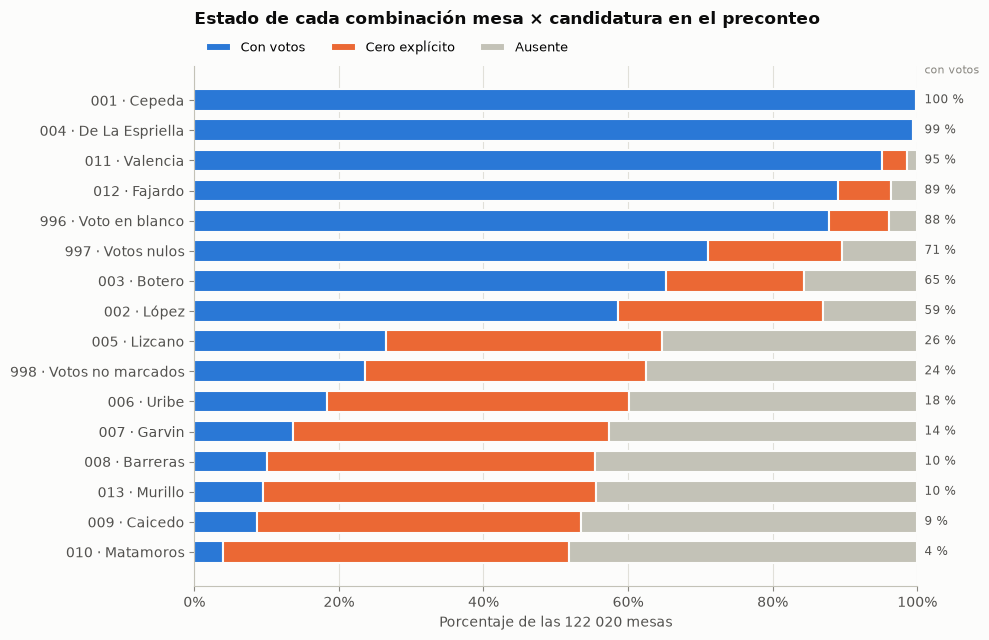

estado,Con votos,Cero explícito,Ausente
candidato,,,
001 · Cepeda,99.9,0.1,0.0
004 · De La Espriella,99.4,0.2,0.3
011 · Valencia,95.1,3.5,1.4
012 · Fajardo,89.0,7.4,3.6
996 · Voto en blanco,87.8,8.3,3.9
997 · Votos nulos,71.0,18.6,10.3
003 · Botero,65.2,19.2,15.6
002 · López,58.6,28.4,13.0
005 · Lizcano,26.5,38.2,35.3


In [6]:
estado = (precon.assign(estado=np.where(precon["votos"] > 0, "Con votos", "Cero explícito"))
          .groupby(["candidato", "estado"]).size().unstack(fill_value=0))
estado["Ausente"] = N_MESAS - estado.sum(axis=1)
estado_pct = (100 * estado[["Con votos", "Cero explícito", "Ausente"]] / N_MESAS).sort_values("Con votos")

fig, ax = plt.subplots(figsize=(10, 6.5))
izquierda = np.zeros(len(estado_pct))
etiquetas = [etiqueta_cand[c] for c in estado_pct.index]
for columna, color in zip(estado_pct.columns, [AZUL, NARANJA, GRIS_AUSENTE]):
    ax.barh(etiquetas, estado_pct[columna], left=izquierda, color=color, label=columna,
            height=0.72, edgecolor=FONDO, linewidth=1.5)
    izquierda += estado_pct[columna].to_numpy()
for y, valor in enumerate(estado_pct["Con votos"]):
    ax.text(101, y, f"{valor:.0f} %", va="center", ha="left", color=TINTA_2, fontsize=8.5)

ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(axis="y", visible=False)
ax.set_xlabel("Porcentaje de las 122 020 mesas")
ax.set_title("Estado de cada combinación mesa × candidatura en el preconteo", pad=30)
ax.legend(ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9)
ax.text(101, len(estado_pct) - 0.2, "con votos", ha="left", va="bottom", color=TINTA_SUAVE, fontsize=8)
plt.tight_layout()
plt.show()

display(estado_pct.round(1).rename(index=etiqueta_cand).iloc[::-1])

#### Interpretación

- **Solo dos candidaturas tienen votos en casi todas las mesas:** `001` (99,9 %) y `004` (99,4 %). Desde la `011` hacia abajo, la proporción de mesas con votos cae rápido. En la `010` es apenas del 3,9 %.
- **En las candidaturas pequeñas, "ausente" y "cero explícito" pesan casi lo mismo.** De la `005` a la `010`, la `013` y el código `998`, cada estado ocupa entre el 35 % y el 48 % de las mesas. Son la misma situación (la candidatura no recibió votos en esa mesa) escrita de dos formas distintas en el archivo.
- **Consecuencia para la preparación:** al pasar a una fila por mesa, ambos estados deben recibir el mismo tratamiento. La sección 3.5 comprueba con el escrutinio que las filas ausentes equivalen a cero votos.

El gris se usa para "ausente" porque representa la falta de fila, no una categoría de votos. La tabla debajo de la gráfica da los valores exactos.

### **3.2. Filas ausentes por departamento**
---

Si las filas ausentes fueran un error de captura, se esperaría que se concentraran en algunos departamentos. El mapa de calor muestra, para cada departamento y candidatura, el porcentaje de mesas que **no traen fila**. Los departamentos se ordenan de mayor a menor número de mesas y las candidaturas de mayor a menor ausencia nacional.

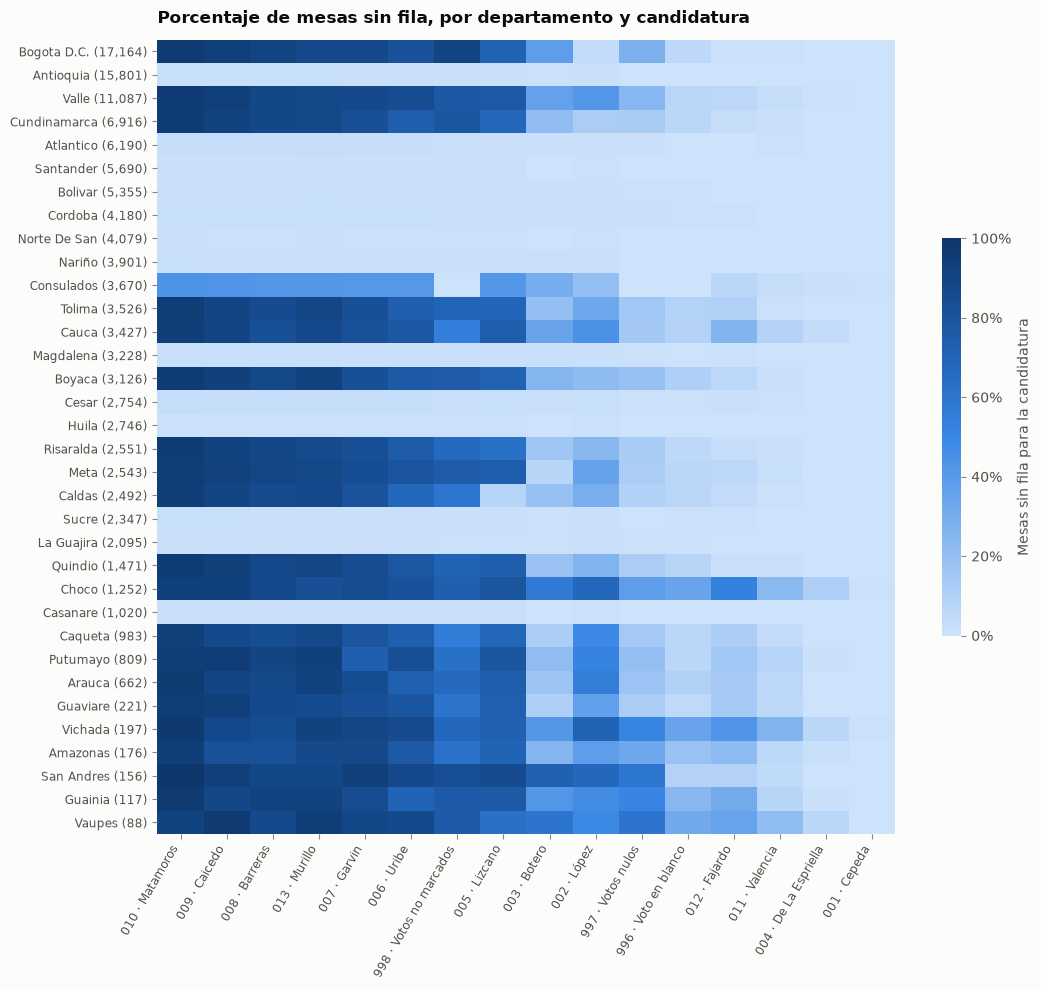

In [7]:
divipol = leer_catalogo(
    "DIVIPOL", [2, 3, 2, 2, 12, 30, 40, 1, 8, 8, 6, 2, 30],
    ["dep", "mun", "zona", "puesto", "dep_nombre", "mun_nombre", "puesto_nombre",
     "indicador_puesto", "potencial_hombres", "potencial_mujeres", "n_mesas",
     "comuna", "comuna_nombre"])
nombre_dep = divipol.drop_duplicates("dep").set_index("dep")["dep_nombre"].str.title()

mesas_dep = mesas.groupby("dep").size()
presentes = precon.groupby(["dep", "candidato"]).size().unstack(fill_value=0)
ausencia_dep = 100 * (1 - presentes.div(mesas_dep, axis=0))
ausencia_dep = ausencia_dep.loc[mesas_dep.sort_values(ascending=False).index,
                                estado_pct.sort_values("Ausente", ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 10))
im = ax.imshow(ausencia_dep, aspect="auto", vmin=0, vmax=100,
               cmap=plt.matplotlib.colors.LinearSegmentedColormap.from_list("azules", AZULES))
ax.set_xticks(range(ausencia_dep.shape[1]), [etiqueta_cand[c] for c in ausencia_dep.columns],
              rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(ausencia_dep.shape[0]),
              [f"{nombre_dep.get(d, d)} ({mesas_dep[d]:,})" for d in ausencia_dep.index], fontsize=8.5)
ax.grid(False)
for lado in ax.spines.values():
    lado.set_visible(False)
barra = fig.colorbar(im, ax=ax, shrink=0.5, format=mtick.PercentFormatter())
barra.set_label("Mesas sin fila para la candidatura", color=TINTA_2)
barra.outline.set_visible(False)
ax.set_title("Porcentaje de mesas sin fila, por departamento y candidatura")
plt.tight_layout()
plt.show()

#### Interpretación

Las filas ausentes **no están repartidas al azar: dependen del departamento.** El mapa muestra dos grupos casi sin términos medios:

- **Departamentos sin ausencias.** Antioquia, Atlántico, Santander, Bolívar, Córdoba, Norte de Santander, Nariño, Magdalena, Cesar, Huila, Sucre, La Guajira y Casanare tienen cerca de 0 % de filas ausentes en todas las candidaturas. Sus mesas traen las 16 filas, incluidas las que tienen cero votos.
- **Departamentos con ausencias.** En Bogotá, Valle, Cundinamarca, Tolima, Cauca, Boyacá, el Eje Cafetero, Meta, Chocó y los antiguos territorios nacionales, las candidaturas pequeñas faltan en el 60 %–100 % de las mesas. Allí la fila solo aparece cuando la candidatura tiene votos.
- **Consulados (exterior)** queda en un punto intermedio, con ausencias cercanas al 50 %.

La sección 3.4 lo confirma: el 100 % de las mesas con 16 filas tiene al menos un cero explícito, frente al 2,9 % de las mesas con menos filas. Es decir, el preconteo parece transmitirse con **dos formatos según el territorio**: uno con todas las filas y otro solo con las filas que tienen votos.

**Consecuencias:**
- El número de filas por mesa refleja el formato de transmisión y no el resultado electoral, así que **no debe usarse como variable predictora**.
- Una partición por departamento separaría también los dos formatos, lo que hay que tener en cuenta al validar los modelos.

*Nota:* el catálogo DIVIPOL guarda el nombre del departamento en 12 caracteres, por eso aparece cortado "Norte De San".

### **3.3. Jerarquía territorial: mesas por puesto y por municipio**
---

El diccionario señala que `mun`, `zona`, `puesto` y `mesa` solo identifican algo dentro de su nivel superior. Estas dos gráficas muestran cuántas mesas agrupa cada puesto de votación y cada municipio. Esto importa para la partición de los datos y para comparar mesas del mismo puesto: un puesto con una sola mesa no tiene con qué compararse.

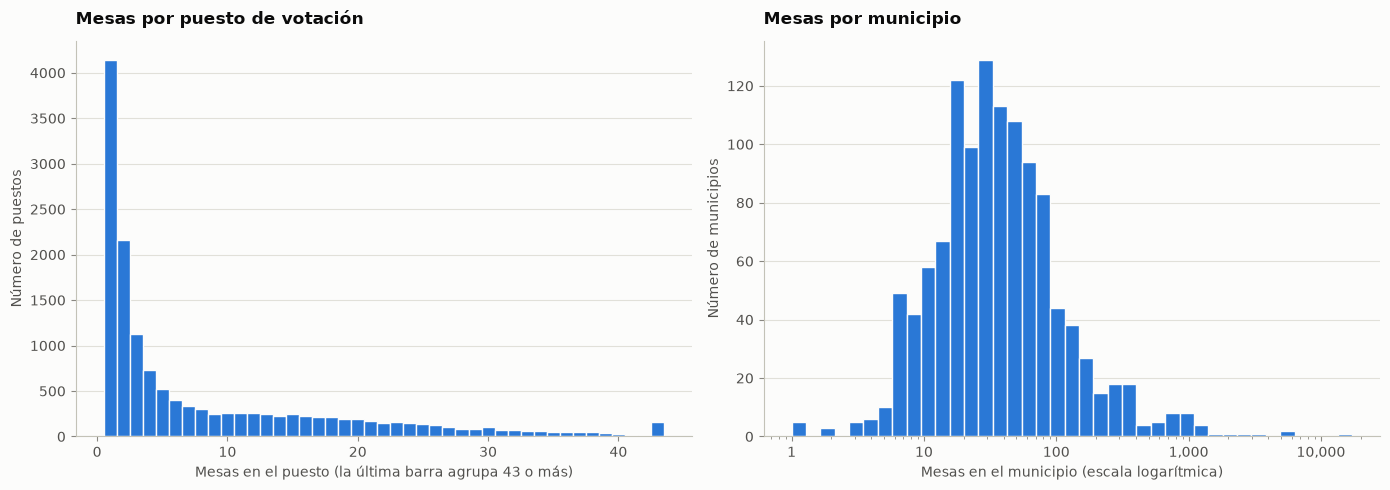

Puestos: 14,438 | mediana de mesas por puesto: 3 | puestos con una sola mesa: 4,146 (28.7 %)
Municipios: 1,189 | mediana de mesas por municipio: 33 | máximo: 17,164 (Bogota D.C., mun 001)
Los 10 municipios con más mesas concentran el 33.5 % de las mesas


In [8]:
mesas_puesto = mesas.groupby(["dep", "mun", "zona", "puesto"]).size()
mesas_mun = mesas.groupby(["dep", "mun"]).size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

tope = int(mesas_puesto.quantile(0.99))
axes[0].hist(mesas_puesto.clip(upper=tope), bins=np.arange(0.5, tope + 1.5), color=AZUL,
             edgecolor=FONDO, linewidth=1)
axes[0].set_title("Mesas por puesto de votación")
axes[0].set_xlabel(f"Mesas en el puesto (la última barra agrupa {tope} o más)")
axes[0].set_ylabel("Número de puestos")
axes[0].grid(axis="x", visible=False)

bordes = np.logspace(0, np.log10(mesas_mun.max()), 40)
axes[1].hist(mesas_mun, bins=bordes, color=AZUL, edgecolor=FONDO, linewidth=1)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:,.0f}"))
axes[1].set_title("Mesas por municipio")
axes[1].set_xlabel("Mesas en el municipio (escala logarítmica)")
axes[1].set_ylabel("Número de municipios")
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print(f"Puestos: {len(mesas_puesto):,} | mediana de mesas por puesto: {mesas_puesto.median():.0f} "
      f"| puestos con una sola mesa: {(mesas_puesto == 1).sum():,} ({100 * (mesas_puesto == 1).mean():.1f} %)")
print(f"Municipios: {len(mesas_mun):,} | mediana de mesas por municipio: {mesas_mun.median():.0f} "
      f"| máximo: {mesas_mun.max():,} ({nombre_dep.get(mesas_mun.idxmax()[0])}, mun {mesas_mun.idxmax()[1]})")
top_mun = mesas_mun.sort_values(ascending=False)
print(f"Los 10 municipios con más mesas concentran el {100 * top_mun.head(10).sum() / N_MESAS:.1f} % de las mesas")

#### Interpretación

- **Puestos.** Hay 14 438 puestos de votación y la mitad tiene 3 mesas o menos. **4 146 puestos (28,7 %) tienen una sola mesa**, así que en ellos no se puede comparar una mesa con sus vecinas del mismo puesto. Esa comparación es una de las ideas para detectar anomalías, y para estas mesas habrá que usar el municipio o la zona como referencia.
- **Municipios.** Hay 1 189 códigos de municipio, incluidos los 67 del exterior. La distribución es muy asimétrica: la mediana es de 33 mesas, pero Bogotá tiene 17 164. **Los 10 municipios con más mesas concentran el 33,5 % de todas las mesas.**
- **Consecuencia para la partición:** una división aleatoria de mesas dejaría casi todos los municipios grandes en entrenamiento y prueba a la vez. Si se agrupa por territorio, conviene estratificar por tamaño para que unas pocas ciudades no dominen un conjunto.

### **3.4. Número de filas según el tamaño de la mesa**
---

El notebook principal muestra que las mesas traen entre 1 y 16 filas. Esta gráfica cruza ese número con el total de votos de la mesa, para ver si las mesas con menos filas son simplemente mesas más pequeñas, donde varias candidaturas no recibieron votos.

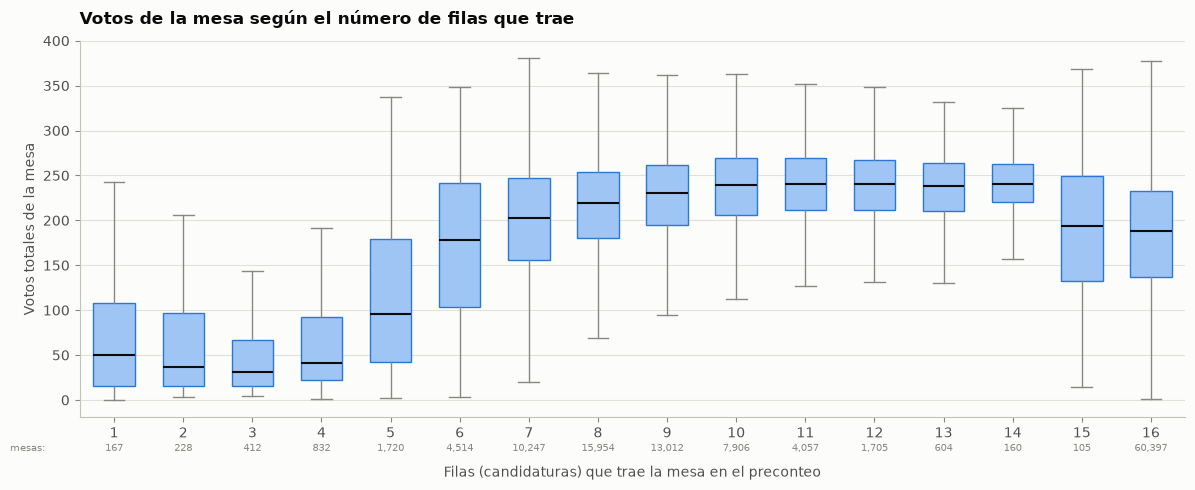

Mesas con 16 filas que tienen al menos un cero explícito: 100.0%


Mesas con menos de 16 filas que tienen al menos un cero explícito: 2.9%


In [9]:
grupos = [mesas.loc[mesas["filas"] == k, "votos"] for k in range(1, 17)]

fig, ax = plt.subplots(figsize=(12, 5))
caja = ax.boxplot(grupos, positions=range(1, 17), widths=0.6, showfliers=False, patch_artist=True,
                  medianprops={"color": TINTA, "linewidth": 1.5},
                  whiskerprops={"color": TINTA_SUAVE}, capprops={"color": TINTA_SUAVE})
for parche in caja["boxes"]:
    parche.set(facecolor="#9ec5f4", edgecolor=AZUL, linewidth=1)
for k, g in zip(range(1, 17), grupos):
    ax.text(k, -0.09, f"{len(g):,}", transform=ax.get_xaxis_transform(), ha="center",
            color=TINTA_SUAVE, fontsize=7.5)
ax.set_xticks(range(1, 17))
ax.set_xlabel("Filas (candidaturas) que trae la mesa en el preconteo", labelpad=18)
ax.set_ylabel("Votos totales de la mesa")
ax.grid(axis="x", visible=False)
ax.set_title("Votos de la mesa según el número de filas que trae")
ax.text(0, -0.09, "mesas:", transform=ax.get_xaxis_transform(), ha="right", color=TINTA_SUAVE, fontsize=7.5)
plt.tight_layout()
plt.show()

print("Mesas con 16 filas que tienen al menos un cero explícito:",
      f"{(precon.groupby(LLAVE_MESA)['votos'].agg(lambda s: (s == 0).any())[mesas.set_index(LLAVE_MESA)['filas'] == 16]).mean():.1%}")
print("Mesas con menos de 16 filas que tienen al menos un cero explícito:",
      f"{(precon.groupby(LLAVE_MESA)['votos'].agg(lambda s: (s == 0).any())[mesas.set_index(LLAVE_MESA)['filas'] < 16]).mean():.1%}")

#### Interpretación

- **De 1 a 14 filas, más filas significa una mesa más grande.** Las mesas con 1 a 4 filas son pequeñas (mediana de 30 a 50 votos). Desde 9 filas, la mediana se estabiliza alrededor de 230–240 votos. Esto concuerda con el formato que solo trae las candidaturas con votos: en una mesa con pocos votantes, pocas candidaturas reciben alguno.
- **Las mesas con 16 filas no siguen ese patrón.** Su mediana (188 votos) es menor que la de las mesas con 9 a 14 filas, y su dispersión es mayor. Corresponden al formato que trae todas las filas, así que reúnen mesas de todos los tamaños.
- **Los ceros explícitos separan los dos formatos casi por completo.** El 100 % de las mesas con 16 filas tiene al menos una candidatura con cero votos escrita en el archivo. Entre las mesas con menos filas, eso solo ocurre en el 2,9 %.

Los números bajo el eje indican cuántas mesas hay en cada grupo. Los grupos de 1 a 4 y de 14 a 15 filas tienen pocas mesas, así que sus cajas son menos estables.

### **3.5. Preconteo frente a escrutinio**
---

El notebook principal analiza cada archivo por separado. Aquí se cruzan por primera vez, con la misma llave de mesa y candidatura. El cruce sirve para dos cosas:

- **Comprobar qué significan las filas ausentes del preconteo**, mirando cuántos votos tiene esa misma combinación en el escrutinio.
- **Ver dónde están las diferencias** entre los dos conteos, que son la base de la variable de discrepancia del proyecto.

El escrutinio se lee con la misma estructura que usa el notebook principal.

In [10]:
COLS_ESC = ["comunicado", "dep", "mun", "zona", "puesto", "mesa", "comuna",
            "corporacion", "circ", "partido", "candidato", "votos"]
escru = pd.read_csv(DATA_DIR / "_ficheros_MMV_4_MMV_9999_ESCRUTINIO.csv", sep=";", header=None,
                    usecols=range(12), names=COLS_ESC, dtype=str, encoding="latin-1")
escru["votos"] = escru["votos"].astype("int64")
escru["zona"] = escru["zona"].str.zfill(3)

LLAVE_FILA = LLAVE_MESA + ["candidato"]
cruce = precon[LLAVE_FILA + ["votos"]].merge(escru[LLAVE_FILA + ["votos"]], on=LLAVE_FILA, how="outer",
                                            suffixes=("_pre", "_esc"), indicator=True)
print(f"Escrutinio: {len(escru):,} filas")
print(cruce["_merge"].value_counts().rename({"both": "En ambos", "left_only": "Solo en preconteo",
                                             "right_only": "Solo en escrutinio"}).to_string())

ausentes = cruce[cruce["_merge"] == "right_only"]
print(f"\nCombinaciones ausentes en el preconteo: {len(ausentes):,}")
print(f"De ellas, con 0 votos en el escrutinio: {(ausentes['votos_esc'] == 0).sum():,} "
      f"({100 * (ausentes['votos_esc'] == 0).mean():.2f} %)")
print("Votos en el escrutinio de las combinaciones ausentes:")
print(ausentes["votos_esc"].describe().round(2).to_string())

Escrutinio: 1,952,320 filas
_merge
En ambos              1479506
Solo en escrutinio     472814
Solo en preconteo           0

Combinaciones ausentes en el preconteo: 472,814
De ellas, con 0 votos en el escrutinio: 464,656 (98.27 %)
Votos en el escrutinio de las combinaciones ausentes:
count    472814.00
mean          0.03
std           0.92
min           0.00
25%           0.00
50%           0.00
75%           0.00
max         191.00


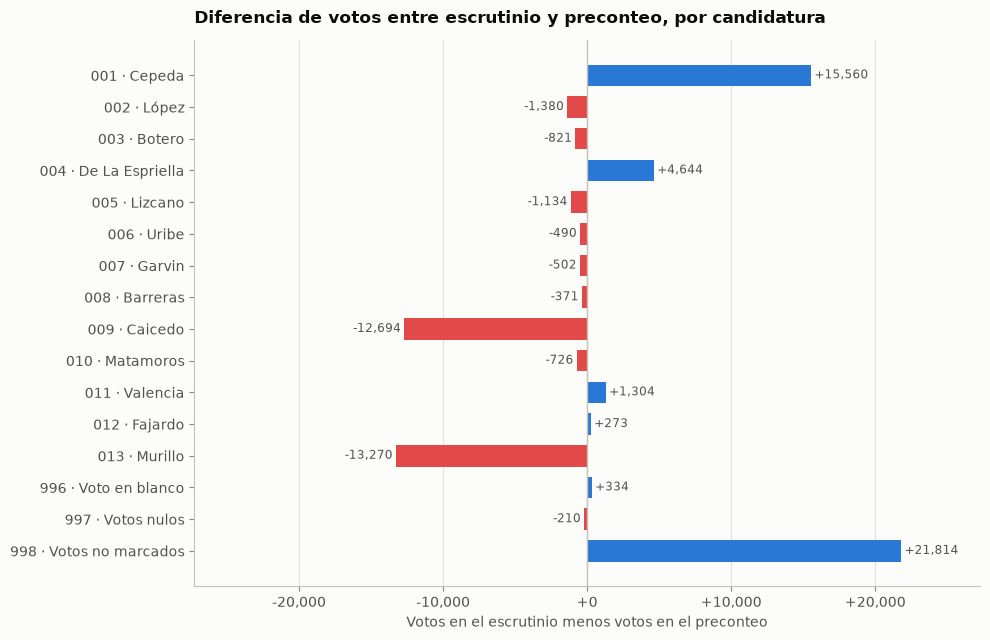

,votos_pre,votos_esc,dif,dif_pct
candidato,,,,
001 · Cepeda,9688361,9703921,15560,0.16
002 · López,225517,224137,-1380,-0.61
003 · Botero,206140,205319,-821,-0.40
004 · De La Espriella,10361499,10366143,4644,0.04
005 · Lizcano,53839,52705,-1134,-2.11
006 · Uribe,28657,28167,-490,-1.71
007 · Garvin,19889,19387,-502,-2.52
008 · Barreras,14108,13737,-371,-2.63
009 · Caicedo,12694,0,-12694,-100.00


In [11]:
cruce[["votos_pre", "votos_esc"]] = cruce[["votos_pre", "votos_esc"]].fillna(0).astype("int64")
cruce["dif"] = cruce["votos_esc"] - cruce["votos_pre"]

por_cand = cruce.groupby("candidato")[["votos_pre", "votos_esc", "dif"]].sum()
por_cand["dif_pct"] = 100 * por_cand["dif"] / por_cand["votos_pre"].where(por_cand["votos_pre"] > 0)

fig, ax = plt.subplots(figsize=(10, 6.5))
orden = por_cand.sort_index(ascending=False)
colores = [AZUL if d >= 0 else ROJO for d in orden["dif"]]
ax.barh([etiqueta_cand[c] for c in orden.index], orden["dif"], color=colores, height=0.68)
ax.axvline(0, color=GRIS_AUSENTE, linewidth=1)
limite = orden["dif"].abs().max()
for y, d in enumerate(orden["dif"]):
    ax.text(d + (0.01 if d >= 0 else -0.01) * limite, y, f"{d:+,}", va="center",
            ha="left" if d >= 0 else "right", color=TINTA_2, fontsize=8.5)
ax.set_xlim(-1.25 * limite, 1.25 * limite)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x:+,.0f}"))
ax.grid(axis="y", visible=False)
ax.set_xlabel("Votos en el escrutinio menos votos en el preconteo")
ax.set_title("Diferencia de votos entre escrutinio y preconteo, por candidatura")
plt.tight_layout()
plt.show()

display(por_cand.rename(index=etiqueta_cand).round(2))

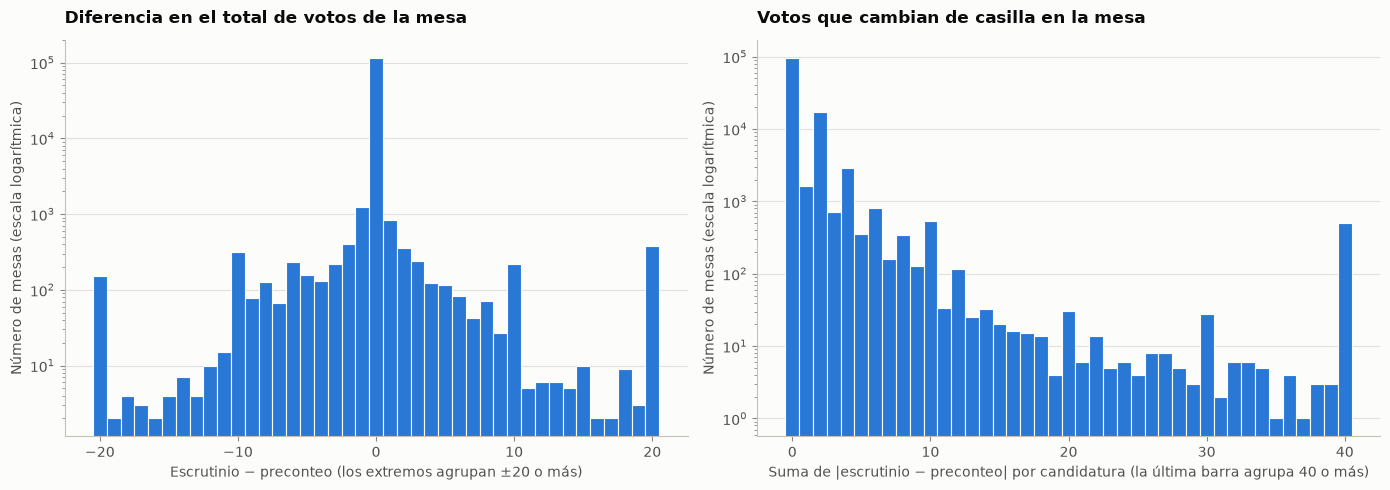

Mesas con el mismo total en ambos conteos: 95.3%
Mesas sin ningún cambio en ninguna candidatura: 79.2%
Diferencia total nacional: +12,331 votos (+0.051 %)
       dif_total    dif_abs
count  122020.00  122020.00
mean        0.10       1.08
std         7.49       8.59
min      -404.00       0.00
50%         0.00       0.00
90%         0.00       2.00
99%         3.00      10.00
max       376.00     490.00


In [12]:
por_mesa = cruce.groupby(LLAVE_MESA).agg(pre=("votos_pre", "sum"), esc=("votos_esc", "sum"),
                                          dif_abs=("dif", lambda s: s.abs().sum()))
por_mesa["dif_total"] = por_mesa["esc"] - por_mesa["pre"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rango = 20
axes[0].hist(por_mesa["dif_total"].clip(-rango, rango), bins=np.arange(-rango - 0.5, rango + 1.5),
             color=AZUL, edgecolor=FONDO, linewidth=0.8)
axes[0].set_yscale("log")
axes[0].set_title("Diferencia en el total de votos de la mesa")
axes[0].set_xlabel(f"Escrutinio − preconteo (los extremos agrupan ±{rango} o más)")
axes[0].set_ylabel("Número de mesas (escala logarítmica)")
axes[0].grid(axis="x", visible=False)

axes[1].hist(por_mesa["dif_abs"].clip(upper=2 * rango), bins=np.arange(-0.5, 2 * rango + 1.5),
             color=AZUL, edgecolor=FONDO, linewidth=0.8)
axes[1].set_yscale("log")
axes[1].set_title("Votos que cambian de casilla en la mesa")
axes[1].set_xlabel(f"Suma de |escrutinio − preconteo| por candidatura (la última barra agrupa {2 * rango} o más)")
axes[1].set_ylabel("Número de mesas (escala logarítmica)")
axes[1].grid(axis="x", visible=False)

plt.tight_layout()
plt.show()

print(f"Mesas con el mismo total en ambos conteos: {(por_mesa['dif_total'] == 0).mean():.1%}")
print(f"Mesas sin ningún cambio en ninguna candidatura: {(por_mesa['dif_abs'] == 0).mean():.1%}")
print(f"Diferencia total nacional: {por_mesa['dif_total'].sum():+,} votos "
      f"({100 * por_mesa['dif_total'].sum() / por_mesa['pre'].sum():+.3f} %)")
print(por_mesa[["dif_total", "dif_abs"]].describe(percentiles=[0.5, 0.9, 0.99]).round(2).to_string())

#### Interpretación

**Las filas ausentes del preconteo equivalen a cero votos.** Ninguna fila del preconteo falta en el escrutinio, y las 472 814 combinaciones que solo están en el escrutinio son exactamente las ausentes del preconteo. **El 98,27 % de ellas tiene 0 votos en el escrutinio** (promedio de 0,03 votos). Las 8 158 restantes sí recibieron votos en el escrutinio. No son datos perdidos, sino diferencias reales entre los dos conteos, y aparecen solas al rellenar las ausentes con 0. Esto cierra la pregunta que el notebook principal deja abierta sobre cómo tratar las combinaciones ausentes.

**Por candidatura:**
- Los candidatos retirados **`009` y `013` pierden el 100 % de sus votos** en el escrutinio (−12 694 y −13 270), mientras que **`998` gana 21 814**. Las dos cifras no coinciden exactamente (25 964 frente a 21 814), así que en `998` también hay otros movimientos.
- Entre las demás candidaturas, las mayores diferencias absolutas son de `001` (+15 560) y `004` (+4 644). En proporción son pequeñas: 0,16 % y 0,04 %.
- **Las candidaturas pequeñas pierden más en proporción:** entre el 1,7 % y el 2,6 % (`005` a `008`) y hasta el 12,9 % (`010`). Es un patrón que vale la pena revisar en la fase de modelado.

**Por mesa:**
- **El 95,3 % de las mesas tiene el mismo total en los dos conteos y el 79,2 % no cambia en ninguna candidatura.** La diferencia nacional es de +12 331 votos (+0,051 %).
- En la gráfica de la derecha predominan los valores pares. Cuando un voto pasa de una candidatura a otra, se cuenta dos veces: una donde se resta y otra donde se suma. El traslado de `009` y `013` a `998` también produce este efecto.
- **Hay picos en ±10 votos**, y en 10, 20 y 30 en la gráfica de la derecha, por encima de lo que sugiere la caída de la distribución. Es compatible con errores en el dígito de las decenas al transcribir el formulario. Es una hipótesis para verificar, no una conclusión.

**Consecuencias para la variable de discrepancia:**
- Es **poco frecuente y muy desbalanceada**: la mayoría de las mesas vale 0.
- Es **discreta y con picos**, lo que conviene tener en cuenta al elegir la función de pérdida o al convertirla en una etiqueta binaria.
- **El traslado de `009` y `013` a `998` debe aislarse** antes de calcularla, por ejemplo uniendo esas tres candidaturas en una sola. Si no, más de 25 000 votos de diferencia quedarían marcados como discrepancia cuando son una regla administrativa.